In [111]:
import sys
from pathlib import Path
import numpy as np
import yaml
import jax
import gc
from tqdm.notebook import tqdm
from dataclasses import replace
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection

ROOT = Path("/home/kzeleznikar/IJS-F1/Koda")
CFG = ROOT / "EI_cutoff" / "config" / "config_ibz.yaml"

# Ensure the root folder is in Python's search path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import EI.ei_unified as eu
from EI_baths.phase_map_plots import plot_maps, scan_maps
from EI_baths.fixed_baths import (
    plot_bz,
    plot_dispersion,
    plot_energy,
    plot_xi,
    solve_state,
    solve_teff,
)
from utils.cosmetics import apply_plt_style
from utils.logger import logger
from utils.plotting_utils import Plotter
import EI.ei_unified as eu
import EI.ei_jax_2 as ej
import EI.ei_phonon as pb
from EI.ei_anderson import solve_anderson

from utils.logger import logger, tqdm_bar
from utils.plotting_utils import Plotter, plot_cmap, format_ax, add_legend, plot_cmap, plot_phase_diag, color_map
from EI_baths.fixed_baths import k_path, take_path, color_line, solve_state, plot_dispersion


apply_plt_style()
pt = Plotter(show=True, close=False)

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)

FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

In [112]:
from matplotlib.colors import SymLogNorm
import matplotlib.pyplot as plt
import colormaps as cmaps
import jax.numpy as jnp
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
from utils.cosmetics import SET1_LIST

In [113]:
import time
from dataclasses import replace
import EI.ei_cavity as cv
import EI.ei_ibz as ibz
with CFG.open("r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

md = cfg["model"]
eq = cfg["equilibrium"]
sc = cfg["scan"]
op = cfg["open_system"]
nk = md["nk"]
bp = md["band"]["pars"]
taeV = 0.1
bd = eu.tb_2d(nk["scan"], **bp)
p = eu.MFPars(**md["mean_field"])

s0 = eu.solve_eq(bd, p, **eq["initial"], **eq["solve"])
d0, m0 = max(abs(float(s0.d)), 1.0e-12), float(s0.m)
tc = float(eu.critical_temperature(bd, p, **eq["critical"]))
t1, t2 = 0.9 * tc, 0.5 * tc  # photon, phonon

kriticna temp bisekcija:   0%|          | 0/80 [00:00<?, ?it/s]

In [114]:
logger.info(f"Delta_0 = {d0} = {d0 *taeV/(8.617 * 1e-5)} K")
logger.info(f"m = {m0}")
logger.info(f"T_c = {tc} = {tc *taeV /(8.617 * 1e-5)} K")

[18:34:15] [INFO    ] Delta_0 = 0.0841290108447073 = 97.63143883568212 K
[18:34:15] [INFO    ] m = -0.9956695984745043
[18:34:15] [INFO    ] T_c = 0.04899871819413812 = 56.862850405173624 K


In [115]:
bc = op["bath"]
fn = getattr(pb, bc["rate"])
bq = dict(bc["pars"])
ov = bc["baths"]  # (photon, phonon)
gp, ph = (fn(t, bd.k, name=f"bath_{i + 1}", **{**bq, **o})
          for i, (t, o) in enumerate(zip((t1, t2), ov)))

gp0 = replace(gp, dip=0.0)
cb = cv.CavityBath(t=t1, w0=gp.w0, gam=gp.gam, ta=bp["ta"], tb=bp["tb"],
                   c=gp.cs, amp=gp.amp, a0=gp.a0)
ph0 = replace(ph, amp=0.0)  # zero phonons, pack still needs a grid bath

In [116]:
omega_0=ov[0]["w0"]

print(2 * d0 / (omega_0 + ov[0]["gam"]))


1.0855356238026748


In [117]:
gw = (1.0, 2.0)  # s window
bi, ib = ibz.tb_2d_ibz(nk["scan"], **bp)

gp0, ph = (fn(t, ib.kf, name=f"bath_{i + 1}", **{**bq, **o})
           for i, (t, o) in enumerate(zip((t1, t2), ov)))

cb = cv.CavityBath(t=t1, w0=gp0.w0, gam=gp0.gam, ta=bp["ta"], tb=bp["tb"],
                   c=gp0.cs, amp=gp0.amp, a0=gp0.a0)

print(cb)

CavityBath(t=0.04409884637472431, w0=0.15, gam=0.005, ta=1.0, tb=-1.0, c=3945.0, amp=100000000.0, alpha=0.0072973525205055605, a0=1.0, name='cavity')


In [119]:
si = eu.solve_eq(bi, p, t=2 * tc, d=max(d0, 1.0e-3), m=m0, **{**eq["solve"], "prog": False})
kw = dict(mix=(0.05, 0.05, 0.05), tol=1.0e-4, nmax=10000, chk=10, prog=True, jtol=1.0e-2, pc=True)

sol = {}
for q, bb in {"grid": (gp0, ph), "cav": (cb, ph)} .items():
    wb = ibz.WinBaths(bb, ib, *gw)
    sol[q] = ej.solve_fixed(bi, p, ibz.freeze(si.n, bi, p, wb), wb,
                            d=float(si.d), m=float(si.m), **kw)
    logger.info(f"{q}: d/d0 = {sol[q].d / d0:.5f}, m = {sol[q].m:.5f}, "
                f"err = {sol[q].err:.1e}, ok = {sol[q].ok}")

Fixed EI JAX:   0%|          | 0/1000 [00:00<?, ?it/s]

KeyboardInterrupt: 

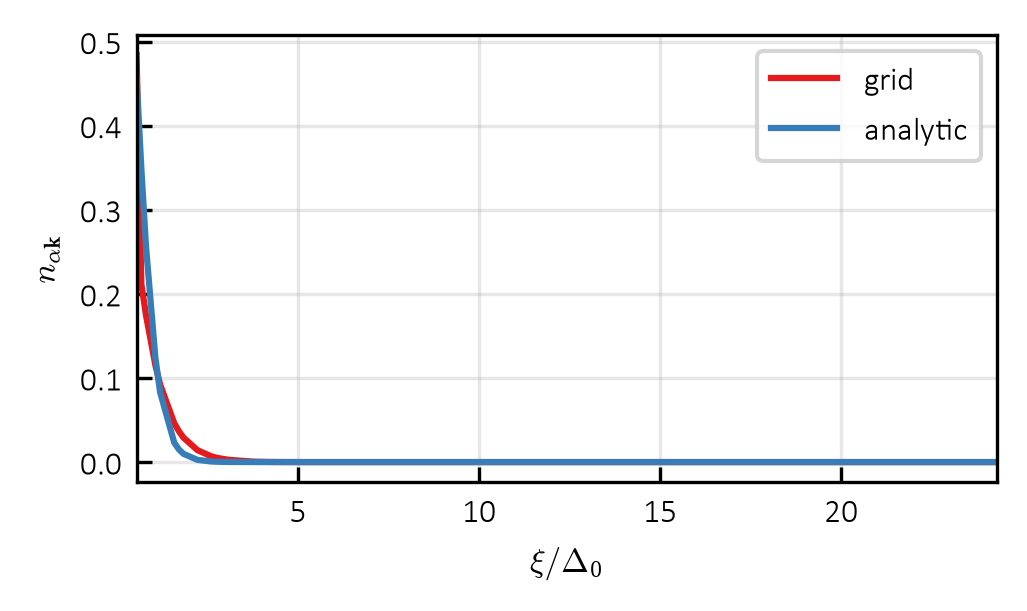

In [ ]:
wi, _ = ibz.win_index(ib, *gw)
fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
xs = []
for i, (q, lb) in enumerate((("grid", r"grid"),
                             ("cav", r"analytic"))):
    s_ = sol[q]
    xi_d0 = 0.5 * (s_.st.eah - s_.st.ebh)[wi] / d0
    nalpha = s_.n[0][wi]

    sort_idx = np.argsort(xi_d0)
    xi_d0_sort = xi_d0[sort_idx]
    nalpha_sort = nalpha[sort_idx]

    xs.append(xi_d0)
    # ax.scatter(xi_d0, nalpha, s=3, color=SET1_LIST[i], label=lb)
    ax.plot(xi_d0_sort , nalpha_sort, color=SET1_LIST[i], label=lb)
xs = np.concatenate(xs)
ax.set_xlim(xs.min(), xs.max())
ax.set_xlabel(r"$\xi/\Delta_0$")
ax.set_ylabel(r"$n_{\alpha\mathbf{k}}$")
ax.grid(alpha=0.3)
ax.legend(markerscale=3)
ax.tick_params(which="both", direction="in")
plt.tight_layout()

In [ ]:
import jax.numpy as jnp
import EI.ei_phonon as pb


def win_in(st, wb, chunk=64):
    """Unweighted sum_k' Gamma(k' -> alpha_k), k in the IBZ window: (from alpha_k', from beta_k')."""
    bp = ibz.pack_win(wb)
    ni, nf = bp.mult.size, bp.idx.size
    a, b, e = jnp.concatenate((st.u, st.v)), jnp.concatenate((-st.v, st.u)), st.e.reshape(-1)
    jf = jnp.concatenate((bp.idx, bp.idx + ni))  # all full grid sources, both bands
    y = jnp.column_stack((e[jf], a[jf], b[jf], jnp.tile(bp.pk.k, (2, 1))))
    out = []
    for c0 in range(0, bp.wi.size, chunk):  # alpha targets in chunks, memory chunk x 2N
        wi = bp.wi[c0:c0 + chunk]
        x = jnp.column_stack((e[wi], a[wi], b[wi], bp.ki[wi]))
        r = pb._pair(x, y, bp.pk)[0]  # rate into the target
        r = jnp.where(bp.rep[wi][:, None] != jnp.arange(2 * nf)[None, :], r, 0.0)  # no self term
        gaa, gba = r[:, :nf].sum(1) / nf, r[:, nf:].sum(1) / nf
        if bp.pk.cav is not None:  # analytic photons, beta_k -> alpha_k only
            gba = gba + cv.local(st.e[:, wi], st.u[wi], st.v[wi], bp.ki[wi], bp.pk.cav)[0]
        out.append(np.asarray(jnp.stack((gaa, gba))))
    return np.concatenate(out, 1)

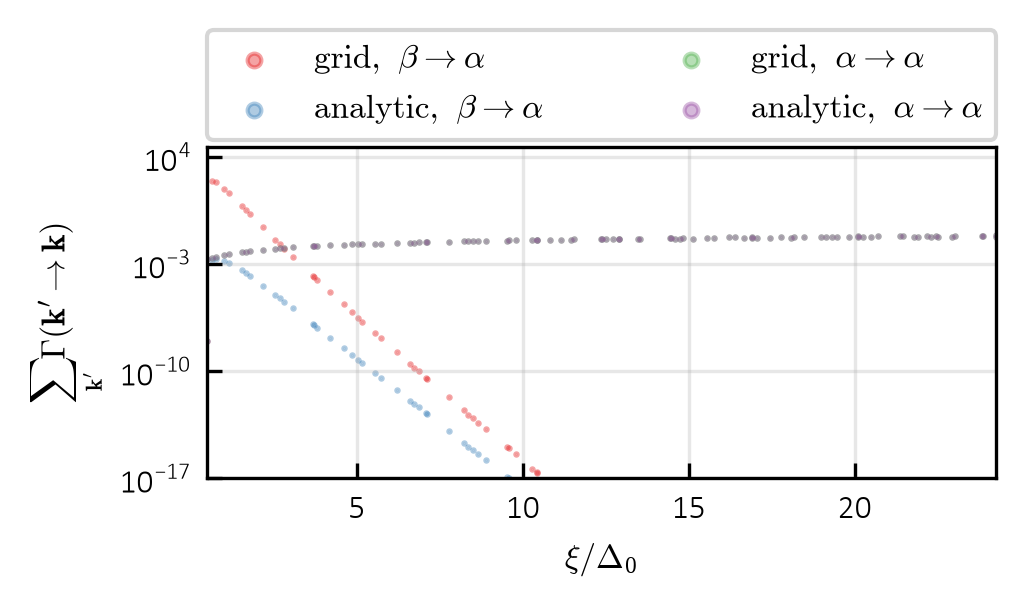

In [ ]:
wi, _ = ibz.win_index(ib, *gw)
st = ej.mf_state(bi, p, d0, m0)
gg = win_in(st, ibz.WinBaths((gp0, ph), ib, *gw))  # photons and phonons on the grid
ga = win_in(st, ibz.WinBaths((cb, ph), ib, *gw))  # photons analytic, phonons on the grid
xi_d0 = 0.5 * (np.asarray(st.eah) - np.asarray(st.ebh))[wi] / d0

fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
for i, (z, lb) in enumerate(((gg[1], r"$\mathrm{grid},\ \beta\to\alpha$"),
                             (ga[1], r"$\mathrm{analytic},\ \beta\to\alpha$"),
                             (gg[0], r"$\mathrm{grid},\ \alpha\to\alpha$"),
                             (ga[0], r"$\mathrm{analytic},\ \alpha\to\alpha$"))):
    ax.scatter(xi_d0, z, s=0.3, color=SET1_LIST[i], label=lb, alpha=0.4)
ax.set_yscale("log")
ax.set_xlim(xi_d0.min(), xi_d0.max())
ax.set_ylim(max(1e-17, min(gg.min(), ga.min())))
ax.set_xlabel(r"$\xi/\Delta_0$")
ax.set_ylabel(r"$\sum_{\mathbf{k}'}\Gamma(\mathbf{k}'\to\mathbf{k})$")
ax.grid(alpha=0.3)
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left",
          mode="expand", borderaxespad=0, ncol=2, markerscale=6)
ax.tick_params(which="both", direction="in")
plt.tight_layout()

In [42]:
xi_d0[0] *d0 #approx 0.05, kot predicted

np.float64(0.041122678906862165)

In [49]:
t2 = 0.3 * tc
ph = fn(t2, ib.kf, name="bath_2", **{**bq, **ov[1]})  # phonons fixed at T2
t1s = np.linspace(0.05, 4.0, 20) * tc  # photon temperatures
amps = gp0.amp * np.array([1.0, 1e4, 1e6, 1e8])  # photon amplitudes

si = eu.solve_eq(bi, p, t=t2, d=max(d0, 1.0e-3), m=m0, **{**eq["solve"], "prog": False})
kw = dict(mix=(0.5, 0.5, 0.1), tol=1.0e-4, nmax=3000, chk=10, prog=False, jtol=1.0e-2, pc=True)

dg = np.full((amps.size, t1s.size), np.nan)
for i, a in enumerate(amps):
    n, d, m = None, float(si.d), float(si.m)  # restart every amp from equilibrium at T2
    for j, t1 in enumerate(tqdm(t1s, desc=f"amp={a:.1e}")):
        cb = cv.CavityBath(t=t1, w0=gp0.w0, gam=gp0.gam, ta=bp["ta"], tb=bp["tb"],
                           c=gp0.cs, amp=a, a0=gp0.a0)
        wb = ibz.WinBaths((cb, ph), ib, *gw)
        n0 = ibz.freeze(si.n if n is None else n, bi, p, wb)
        s = ej.solve_fixed(bi, p, n0, wb, d=max(d, 1.0e-4), m=m, **kw)
        n, d, m = s.n, float(s.d), float(s.m)  # continuation in T1
        dg[i, j] = abs(s.d)
        if not s.ok:
            logger.info(f"amp={a:.1e}, T1/Tc={t1 / tc:.3f}: not converged, err={s.err:.1e}")

amp=1.0e+00:   0%|          | 0/20 [00:00<?, ?it/s]

amp=1.0e+04:   0%|          | 0/20 [00:00<?, ?it/s]

[17:46:07] [INFO    ] amp=1.0e+04, T1/Tc=1.921: not converged, err=4.1e-03
[17:46:10] [INFO    ] amp=1.0e+04, T1/Tc=2.129: not converged, err=1.5e-02
[17:46:14] [INFO    ] amp=1.0e+04, T1/Tc=2.337: not converged, err=1.4e-02
[17:46:17] [INFO    ] amp=1.0e+04, T1/Tc=2.545: not converged, err=1.8e-02
[17:46:21] [INFO    ] amp=1.0e+04, T1/Tc=2.753: not converged, err=3.6e-02
[17:46:24] [INFO    ] amp=1.0e+04, T1/Tc=2.961: not converged, err=3.5e-02
[17:46:28] [INFO    ] amp=1.0e+04, T1/Tc=3.168: not converged, err=4.4e-02
[17:46:31] [INFO    ] amp=1.0e+04, T1/Tc=3.376: not converged, err=1.0e-02
[17:46:34] [INFO    ] amp=1.0e+04, T1/Tc=3.584: not converged, err=2.7e-02
[17:46:38] [INFO    ] amp=1.0e+04, T1/Tc=3.792: not converged, err=1.4e-02
[17:46:41] [INFO    ] amp=1.0e+04, T1/Tc=4.000: not converged, err=3.4e-02


amp=1.0e+06:   0%|          | 0/20 [00:00<?, ?it/s]

[17:46:45] [INFO    ] amp=1.0e+06, T1/Tc=0.882: not converged, err=1.1e-02
[17:46:49] [INFO    ] amp=1.0e+06, T1/Tc=1.089: not converged, err=3.9e-02
[17:46:52] [INFO    ] amp=1.0e+06, T1/Tc=1.297: not converged, err=2.6e-02
[17:46:56] [INFO    ] amp=1.0e+06, T1/Tc=1.505: not converged, err=5.9e-02
[17:46:59] [INFO    ] amp=1.0e+06, T1/Tc=1.713: not converged, err=1.8e-02
[17:47:03] [INFO    ] amp=1.0e+06, T1/Tc=1.921: not converged, err=3.9e-02
[17:47:06] [INFO    ] amp=1.0e+06, T1/Tc=2.129: not converged, err=7.4e-02
[17:47:10] [INFO    ] amp=1.0e+06, T1/Tc=2.337: not converged, err=6.5e-02
[17:47:13] [INFO    ] amp=1.0e+06, T1/Tc=2.545: not converged, err=1.0e-01
[17:47:17] [INFO    ] amp=1.0e+06, T1/Tc=2.753: not converged, err=1.0e-01
[17:47:20] [INFO    ] amp=1.0e+06, T1/Tc=2.961: not converged, err=1.1e-01
[17:47:24] [INFO    ] amp=1.0e+06, T1/Tc=3.168: not converged, err=1.3e-03
[17:47:27] [INFO    ] amp=1.0e+06, T1/Tc=3.376: not converged, err=7.3e-02
[17:47:31] [INFO    ] amp

amp=1.0e+08:   0%|          | 0/20 [00:00<?, ?it/s]

[17:47:42] [INFO    ] amp=1.0e+08, T1/Tc=0.882: not converged, err=1.7e-02
[17:47:45] [INFO    ] amp=1.0e+08, T1/Tc=1.089: not converged, err=3.7e-02
[17:47:48] [INFO    ] amp=1.0e+08, T1/Tc=1.297: not converged, err=6.1e-02
[17:47:52] [INFO    ] amp=1.0e+08, T1/Tc=1.505: not converged, err=2.4e-02
[17:47:55] [INFO    ] amp=1.0e+08, T1/Tc=1.713: not converged, err=3.8e-02
[17:47:59] [INFO    ] amp=1.0e+08, T1/Tc=1.921: not converged, err=4.4e-02
[17:48:02] [INFO    ] amp=1.0e+08, T1/Tc=2.129: not converged, err=4.3e-02
[17:48:06] [INFO    ] amp=1.0e+08, T1/Tc=2.337: not converged, err=5.8e-02
[17:48:09] [INFO    ] amp=1.0e+08, T1/Tc=2.545: not converged, err=5.7e-02
[17:48:12] [INFO    ] amp=1.0e+08, T1/Tc=2.753: not converged, err=4.0e-02
[17:48:16] [INFO    ] amp=1.0e+08, T1/Tc=2.961: not converged, err=9.0e-02
[17:48:19] [INFO    ] amp=1.0e+08, T1/Tc=3.168: not converged, err=6.9e-02
[17:48:23] [INFO    ] amp=1.0e+08, T1/Tc=3.376: not converged, err=2.1e-02
[17:48:26] [INFO    ] amp

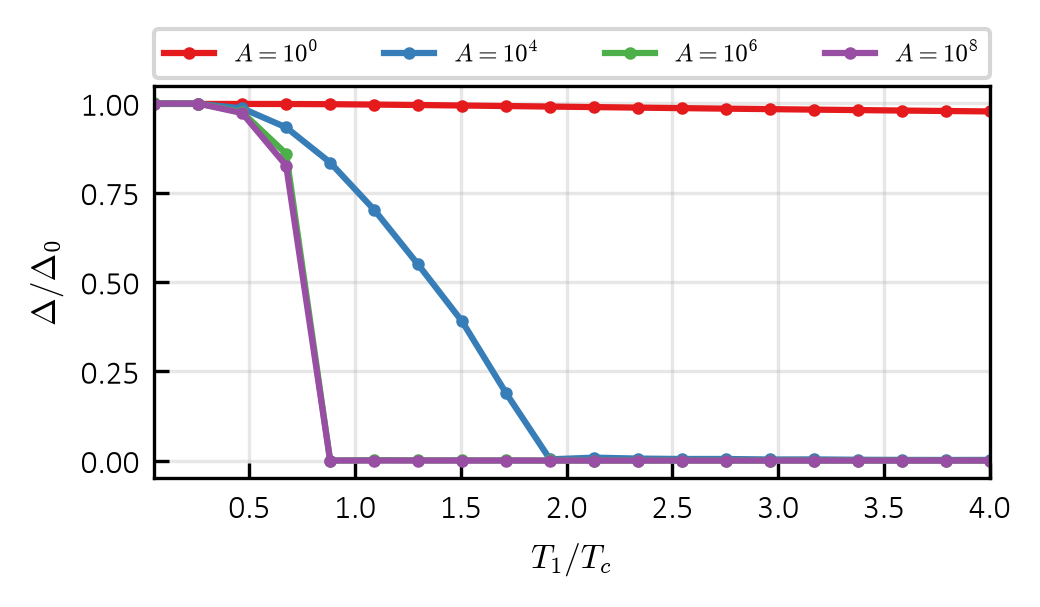

In [ ]:
fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
for i, a in enumerate(amps):
    exp = int(np.round(np.log10(a)))
    ax.plot(t1s / tc, dg[i] / d0, "o-", ms=2, color=SET1_LIST[i], label=rf"$A=10^{{{exp}}}$")
# ax.set_xscale("log")
ax.set_xlim(t1s[0] / tc, t1s[-1] / tc)
ax.set_xlabel(r"$T_1/T_c$")
ax.set_ylabel(r"$\Delta/\Delta_0$")
ax.grid(alpha=0.3)
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand",
          borderaxespad=0, ncol=4, fontsize=6)
ax.tick_params(which="both", direction="in")
plt.tight_layout()
# plt.savefig(FIG_PATH + "OP_T2=0p3_rel_amplitudesBEC.pdf", bbox_inches="tight")
plt.show()

In [45]:
t1 = 0.3 * tc
t2s = np.linspace(0.3, 4.0, 20) * tc  # phonon temperatures
amps = gp0.amp * np.array([1.0, 1e4, 1e6, 1e8])  # photon amplitudes
kw = dict(mix=(0.5, 0.5, 0.1), tol=1.0e-4, nmax=3000, chk=10, prog=False, jtol=1.0e-2, pc=True)

si = eu.solve_eq(bi, p, t=t2s[0], d=max(d0, 1.0e-3), m=m0, **{**eq["solve"], "prog": False})
phs = [fn(t2, ib.kf, name="bath_2", **{**bq, **ov[1]}) for t2 in t2s]  # phonon bath per T2

dg = np.full((amps.size, t2s.size), np.nan)
for i, a in enumerate(amps):
    cb = cv.CavityBath(t=t1, w0=gp0.w0, gam=gp0.gam, ta=bp["ta"], tb=bp["tb"],
                       c=gp0.cs, amp=a, a0=gp0.a0)  # photons fixed at T1
    n, d, m = None, float(si.d), float(si.m)  # restart every amp from equilibrium at the first T2
    for j, (t2, ph) in enumerate(zip(tqdm(t2s, desc=f"amp={a:.1e}"), phs)):
        wb = ibz.WinBaths((cb, ph), ib, *gw)
        n0 = ibz.freeze(si.n if n is None else n, bi, p, wb)
        s = ej.solve_fixed(bi, p, n0, wb, d=max(d, 1.0e-4), m=m, **kw)
        n, d, m = s.n, float(s.d), float(s.m)  # continuation in T2
        dg[i, j] = abs(s.d)
        if not s.ok:
            logger.info(f"amp={a:.1e}, T2/Tc={t2 / tc:.3f}: not converged, err={s.err:.1e}")

amp=1.0e+00:   0%|          | 0/20 [00:00<?, ?it/s]

[17:44:14] [INFO    ] amp=1.0e+00, T2/Tc=1.079: not converged, err=1.5e-04
[17:44:18] [INFO    ] amp=1.0e+00, T2/Tc=1.274: not converged, err=1.5e-03


amp=1.0e+04:   0%|          | 0/20 [00:00<?, ?it/s]

[17:44:27] [INFO    ] amp=1.0e+04, T2/Tc=1.079: not converged, err=4.2e-03
[17:44:31] [INFO    ] amp=1.0e+04, T2/Tc=1.274: not converged, err=1.8e-03


amp=1.0e+06:   0%|          | 0/20 [00:00<?, ?it/s]

[17:44:44] [INFO    ] amp=1.0e+06, T2/Tc=2.442: not converged, err=6.9e-04


amp=1.0e+08:   0%|          | 0/20 [00:00<?, ?it/s]

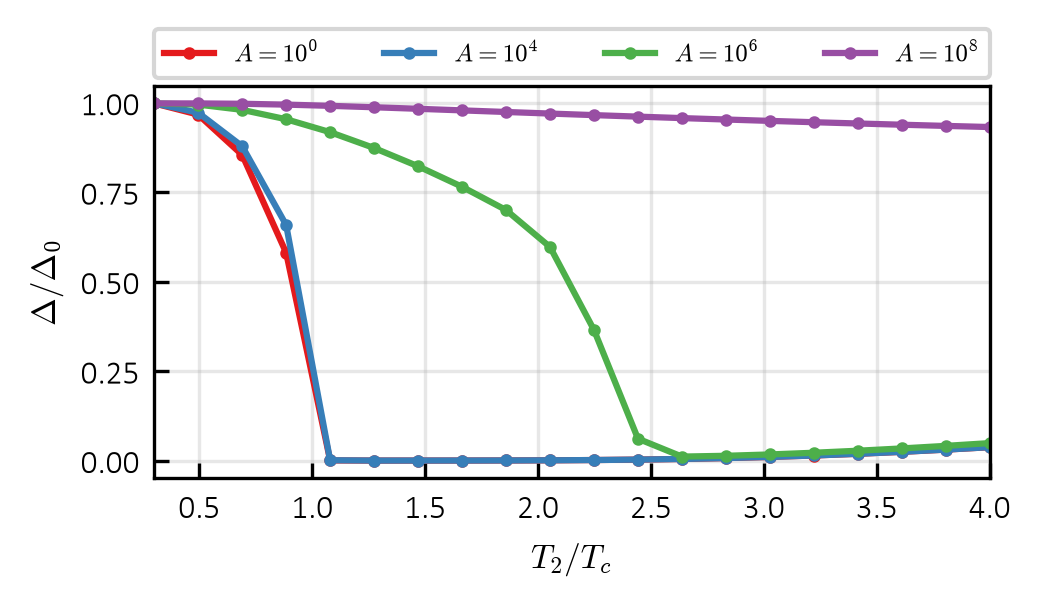

In [ ]:
fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
for i, a in enumerate(amps):
    exp = int(np.round(np.log10(a)))
    ax.plot(t2s / tc, dg[i] / d0, "o-", ms=2, color=SET1_LIST[i], label=rf"$A=10^{{{exp}}}$")
ax.set_xlim(t2s[0] / tc, t2s[-1] / tc)
ax.set_xlabel(r"$T_2/T_c$")
ax.set_ylabel(r"$\Delta/\Delta_0$")
ax.grid(alpha=0.3)
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand",
          borderaxespad=0, ncol=4, fontsize=6)
ax.tick_params(which="both", direction="in")
plt.tight_layout()
# plt.savefig(FIG_PATH + "OP_T1=0p3_rel_amplitudesBEC.pdf", bbox_inches="tight")

plt.show()

In [76]:
t1r = np.linspace(0.25, 2.0, 10)  # T1 / Tc, photons
t2r = np.linspace(0.25, 2.0, 10)  # T2 / Tc, phonons
ds, nw = 1.0e-4, 200              # gap floor, warm up iterations
kf = {**kw, "prog": False, "pc": True}

# mg = lambda a, b: (replace(gp0, t=a), replace(ph, t=b))  # grid photons, c = 3
mc = lambda a, b: (replace(cb, t=a), replace(ph, t=b))   # analytic, c = 3945

In [77]:
def sweep(mk):
    """Gap and imbalance on the (T2, T1) grid, rows = T2."""
    dm = np.full((t2r.size, t1r.size), np.nan)
    mm = np.full_like(dm, np.nan)
    ok = np.zeros(dm.shape, dtype=bool)
    wb = ibz.WinBaths(mk(tc, tc), ib, *gw)
    s0 = (ibz.freeze(si.n, bi, p, wb), float(si.d), float(si.m))
    for i in tqdm(range(t2r.size), desc="T2 sweep"):
        sv = s0
        for j in tqdm(range(t1r.size), leave=False, desc="T1"):
            wb = ibz.WinBaths(mk(t1r[j] * tc, t2r[i] * tc), ib, *gw)
            n0, dv, mv = sv
            sn = ej.solve_fixed(bi, p, n0.copy(), wb, d=max(abs(dv), ds), m=mv, **kf)
            if abs(float(sn.d)) < ds:  # retry from a warm up
                w0_ = ej.solve_fixed(bi, p, sn.n.copy(), wb, d=ds, m=float(sn.m),
                                     **{**kf, "nmax": nw})
                sn = ej.solve_fixed(bi, p, w0_.n.copy(), wb, d=float(w0_.d),
                                    m=float(w0_.m), **kf)
            dm[i, j], mm[i, j], ok[i, j] = sn.d, sn.m, bool(sn.ok)
            if np.isfinite(sn.err):
                sv = (sn.n, float(sn.d), float(sn.m))
                if j == 0:
                    s0 = sv  # next row starts here
    return dm, mm, ok

T2 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

T1:   0%|          | 0/10 [00:00<?, ?it/s]

T1:   0%|          | 0/10 [00:00<?, ?it/s]

T1:   0%|          | 0/10 [00:00<?, ?it/s]

T1:   0%|          | 0/10 [00:00<?, ?it/s]

T1:   0%|          | 0/10 [00:00<?, ?it/s]

... (2 outputs left out)

T1:   0%|          | 0/10 [00:00<?, ?it/s]

T1:   0%|          | 0/10 [00:00<?, ?it/s]

T1:   0%|          | 0/10 [00:00<?, ?it/s]

 analytic unconverged: 37


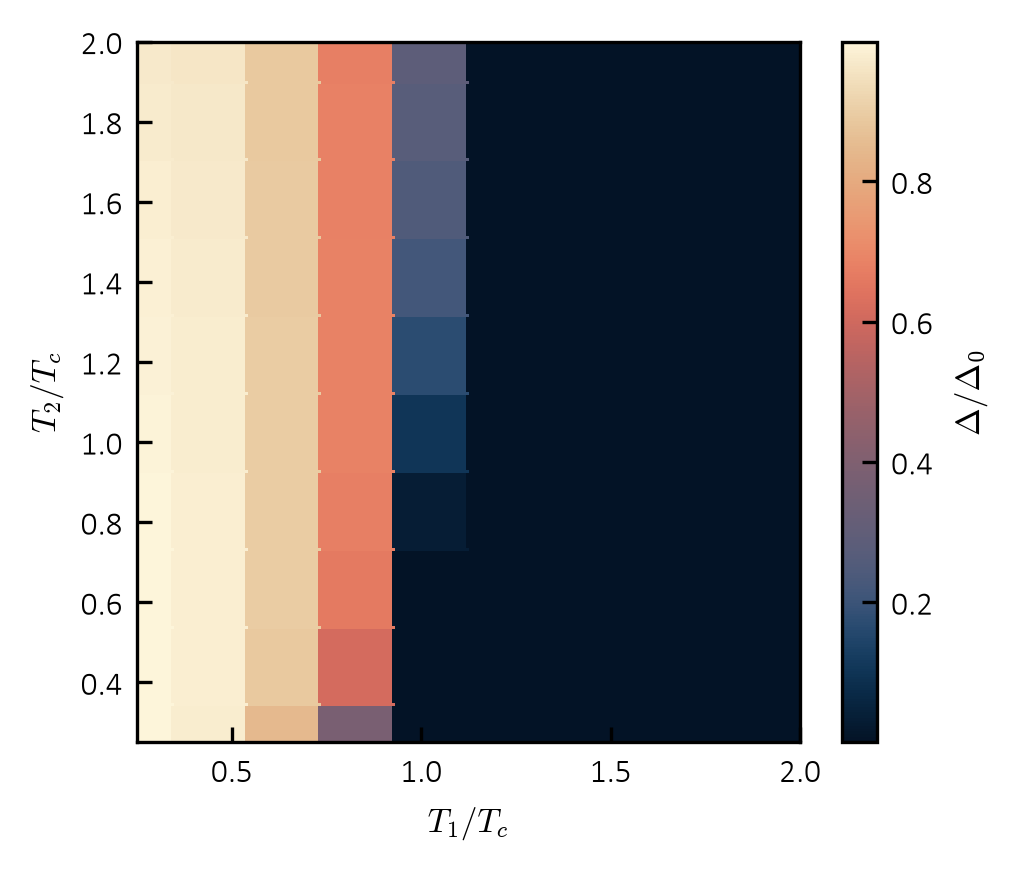

In [78]:
# dg, mgm, okg = sweep(mg)
da, mam, oka = sweep(mc)
# print("unconverged grid:", (~okg).sum(), " analytic:", (~oka).sum())
print(" analytic unconverged:", (~oka).sum())

# fg, _ = plot_cmap(t1r, t2r, dg / d0, r"$\Delta/\Delta_0$", pt=pt)
fa, _ = plot_cmap(t1r, t2r, da / d0, r"$\Delta/\Delta_0$", pt=pt)

# fg.savefig(FIG_PATH + "gap_map_grid_c3.pdf", bbox_inches="tight")
# fa.savefig(FIG_PATH + "gap_map_cav_c3945.pdf", bbox_inches="tight")

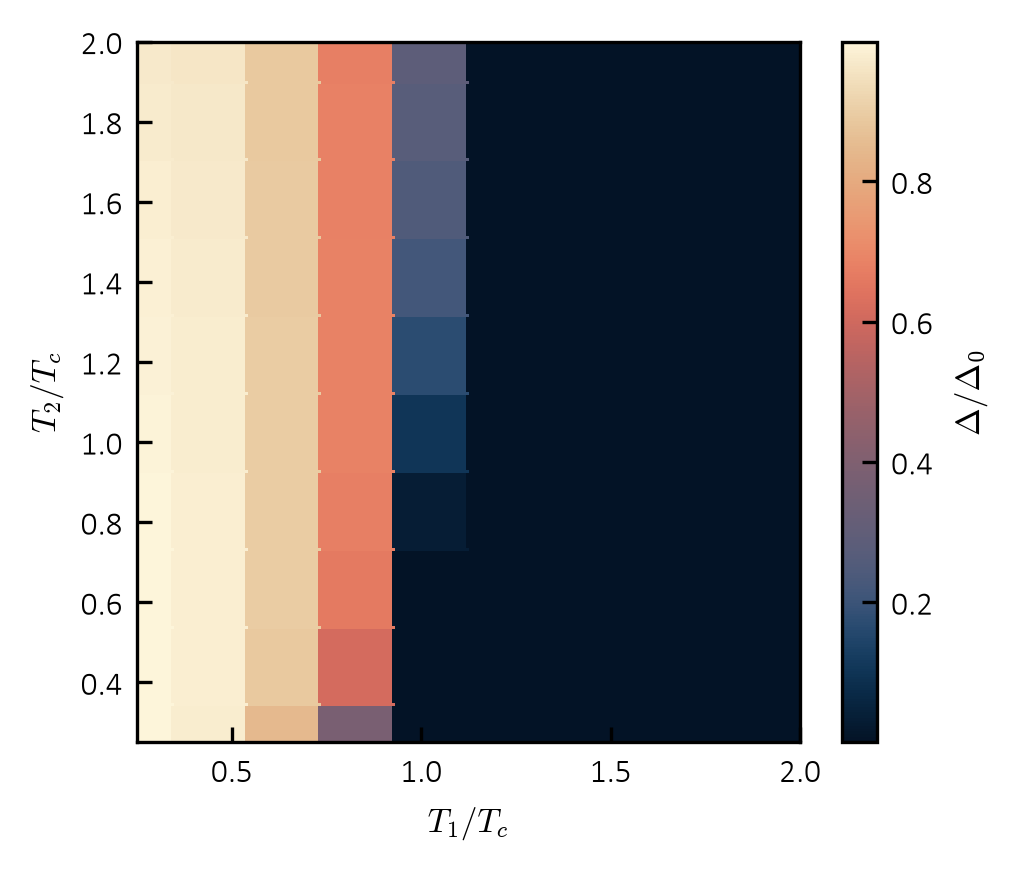

In [ ]:
fa, _ = plot_cmap(t1r, t2r, da / d0, r"$\Delta/\Delta_0$", pt=pt)
# fa.savefig(FIG_PATH + "gap_analytic_cav_strongphotons_scalingsBEC.pdf", bbox_inches="tight")

In [123]:
a1, a2 = 0.8, 1.0  # T1/Tc, T2/Tc
wb = ibz.WinBaths(mc(a1 * tc, a2 * tc), ib, *gw)
sn = ej.solve_fixed(bi, p, ibz.freeze(si.n, bi, p, wb), wb, d=float(si.d), m=float(si.m), **kf)
wi, _ = ibz.win_index(ib, *gw)

st = sn.st
xi = 0.5 * np.asarray(st.eah - st.ebh)[wi]
e = np.asarray(st.e)[0, wi]  # E_alpha = E for symmetric bands
na = np.asarray(sn.n)[0, wi]
hb = 1 - np.asarray(sn.n)[1, wi]  # beta holes, = na if particle hole symmetric
dn = abs(float(sn.d))

# fit logit(n_alpha) = -(E - mu)/T* on the states with a resolvable occupation
lg = np.log(na) - np.log1p(-na)
ok = np.isfinite(lg) & (na > 1e-250)

c1 = -1.0 /(a2 * tc)
c0 = np.mean(lg[ok] - c1 * e[ok])
mf = c0 *a2 * tc
logger.info(f"Delta/Delta_0 = {dn / d0:.3f}, ok = {sn.ok}, "
            f"mu* = {mf:.4f}, T2/Tc = {a2}, T1/Tc = {a1}")

[18:47:50] [INFO    ] Delta/Delta_0 = 0.037, ok = False, mu* = 0.4732, T2/Tc = 1.0, T1/Tc = 0.8


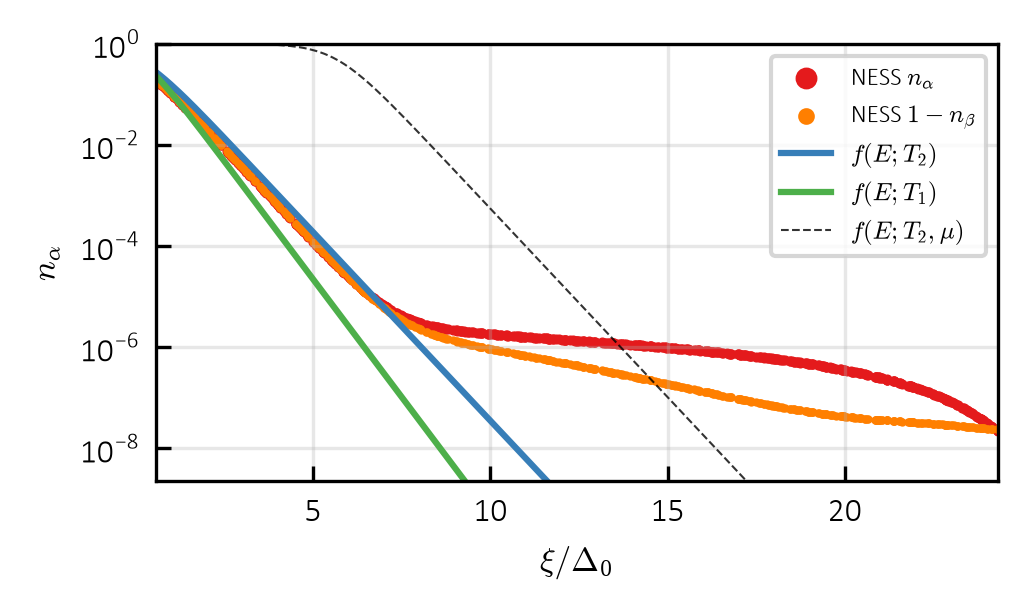

In [124]:
from scipy.special import expit

fd = lambda x, t, mu=0.0: expit(-(x - mu) / t)
o = np.argsort(xi)
fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
ax.scatter(xi / d0, na, s=2, color=SET1_LIST[0], label=r"NESS $n_\alpha$")
ax.scatter(xi / d0, hb, s=1, color=SET1_LIST[4], label=r"NESS $1-n_\beta$")
ax.plot(xi[o] / d0, fd(e[o], a2 * tc), color=SET1_LIST[1], label=r"$f(E;T_2)$")
ax.plot(xi[o] / d0, fd(e[o], a1 * tc), color=SET1_LIST[2], label=r"$f(E;T_1)$")
ax.plot(xi[o] / d0, fd(e[o], a2 * tc, mf), "--", color="k", lw=0.5, alpha=0.8, label=r"$f(E;T_2,\mu)$")
ax.set_yscale("log")
ax.set_ylim(max(na[ok].min() * 0.1, 1e-30), 1)
ax.set_xlim(xi.min() / d0, xi.max() / d0)
ax.set_xlabel(r"$\xi/\Delta_0$")
ax.set_ylabel(r"$n_\alpha$")
ax.grid(alpha=0.3)
ax.legend(fontsize=6, markerscale=3)
ax.tick_params(which="both", direction="in")
plt.tight_layout()
# plt.savefig(FIG_PATH + "NESS_strong_photons_1e8_0p81.pdf", bbox_inches="tight")

In [ ]:
print(cb)

CavityBath(t=0.04409884637472431, w0=0.15, gam=0.005, ta=1.0, tb=-1.0, c=3945.0, amp=100000000.0, alpha=0.0072973525205055605, a0=1.0, name='cavity')
